## Supervised Learning

### Linear Regression

#### Linear Regression example

In [3]:
import numpy as np

In [2]:
np.random.seed(0)
n = 50
x = np.linspace(-3,3,n)
# true underlying polynomial: y = 1-2x + 0.5X^2
y = 1 - 2*x + 0.5*x**2 + np.random.normal(scale=2.0, size=n)

#build design matrix for degree d
def design_matrix(x, d):
    #columns: 1, x, x^2, ...., x^d
    return np.vander(x, N=d+1, increasing=True) # increasing True => [1, x, x^2, ....]
d = 2
X = design_matrix(x, d) # shape(n, d+1)
beta_hat = np.linalg.inv(X.T@X)@X.T@y
print("Estmated coefficient:", beta_hat)
y_pred = X @ beta_hat

Estmated coefficient: [ 1.12121268 -2.47054083  0.55121168]


#### Polynomial Regression example

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

# create synthetic data
np.random.seed(42)
X = np.linspace(-3,3,100)
y = 0.5*X**2 + X + 2 + np.random.randn(100) # quadratic relationship

# Convert ti DataFramce
df = pd.DataFrame({"X":X, "y":y})

# split into train and test set
train_df = df.sample(frac=0.8, random_state=42)
test_df = df.drop(train_df.index)

X_train = train_df[["X"]].values
y_train = train_df[["y"]].values
X_test = test_df[["X"]].values
y_test = test_df[["y"]].values

#3. Polynomial feature transformation ()degree 2)
def polynomial_features(X, degree):
    X_pol = np.ones((X.shape[0], 1))
    for d in range(1, degree+1):
        X_pol = np.c_[X_pol, X**d]
    return X_pol

degree = 2
X_train_poly = polynomial_features(X_train, degree)
X_test_poly = polynomial_features(X_test, degree)

#4. Fit model using normal equation
theta_best = np.linalg.inv(X_train_poly.T @ X_train_poly) @ (X_train_poly.T @ y_train)
print("Model Coefficient:", theta_best.flatten())

#5. Predictions
y_pred = X_test_poly @ theta_best

Model Coefficient: [1.94661927 1.00588054 0.49660544]


In [4]:
print("Predictions: \n")
print(y_pred)

Predictions: 

[[3.28062935]
 [3.16648025]
 [2.08124729]
 [1.73563132]
 [1.69079721]
 [1.61207346]
 [1.46345799]
 [1.46960086]
 [2.04216713]
 [2.1104259 ]
 [2.78782975]
 [3.10205079]
 [4.1004925 ]
 [4.53510273]
 [5.8545823 ]
 [6.22093377]
 [6.60187787]
 [6.79782215]
 [7.61808087]
 [7.83226594]]


In [5]:
#6. Metrics (MAE, MSE, RMSE, R2)
mae = np.mean(np.abs(y_test - y_pred))
mse = np.mean((y_test - y_pred) ** 2)
rmse = np.sqrt(mse)
ss_total = np.sum((y_test - np.mean(y_test))**2)
ss_res = np.sum((y_test - y_pred)**2)
r2 = 1 - (ss_res / ss_total)

print("\n Evaluation Metrics:")
print("MAE:",mae)
print("MSE:",mse)
print("RMSE:",rmse)
print("R2:",r2)


 Evaluation Metrics:
MAE: 0.9800118746966782
MSE: 1.3870295751952806
RMSE: 1.1777221978018757
R2: 0.817156855673273


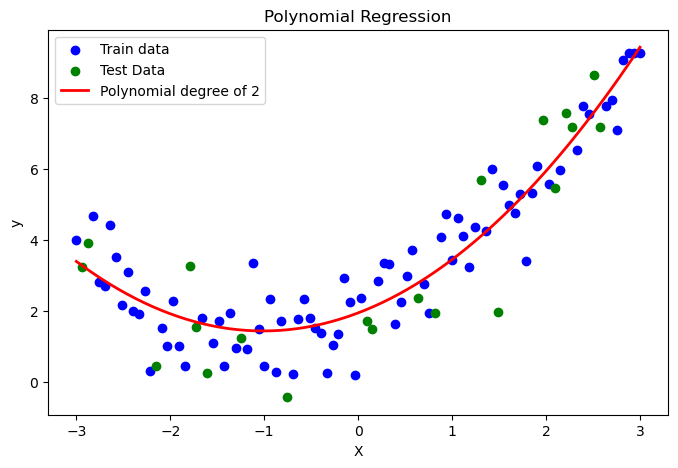

In [6]:
#7. plot the results
X_plot = np.linspace(min(X), max(X), 200).reshape(-1,1)
X_plot_poly = polynomial_features(X_plot, degree)
y_plot = X_plot_poly @ theta_best

plt.figure(figsize = (8,5))
plt.scatter(X_train, y_train, color='blue', label='Train data')
plt.scatter(X_test, y_test, color='green', label='Test Data')
plt.plot(X_plot, y_plot, color='red', linewidth=2, label=f"Polynomial degree of {degree}")
plt.title("Polynomial Regression")
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.show()

## Non linear regression

In [7]:
#1. Generate synthetic non-linear data
np.random.seed(42)
X = np.linspace(0,4,50)
y = 3 * np.exp(0.5* X ) + np.random.normal(scale=2, size=50)

# put into DataFrame for clarity
df = pd.DataFrame({"X":X, "y":y})

#2. transform to linear form: ln(y) = ln(a) + bX
df["ln_y"] = np.log(df["y"])

#3. Apply normal equation to find coefficient 
X_mat = np.vstack([np.ones(len(df)), df["X"]]).T
y_vec = df["ln_y"].values

# ß = (X.TX)^-1 X.Ty
beta = np.linalg.inv(X_mat.T @ X_mat) @ (X_mat.T @ y_vec)
ln_a, b = beta
a = np.exp(ln_a)

print(f"Fitted model: y = {a:.4f} * e^({b:.4f}x)")

# 4. Prediction
df['y_pred'] = a * np.exp(b*df["X"])

Fitted model: y = 2.8322 * e^(0.4880x)



 Evaluation Metrics:
MAE:1.5473
MSE: 3.6043
RMSE: 1.8985
R2: 0.8828


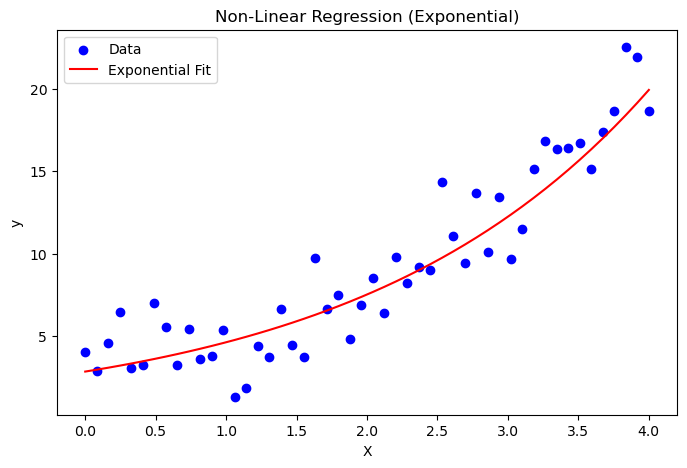

In [8]:
#5. Metrics
mae = np.mean(np.abs(df["y"] - df["y_pred"]))
mse = np.mean((df["y"] - df["y_pred"])**2)
rmse = np.sqrt(mse)
ss_total = np.sum((df["y"] - np.mean(df["y"]))**2)
ss_res = np.sum((df["y"] - df["y_pred"])**2)
r2 = 1 - (ss_res / ss_total)

print("\n Evaluation Metrics:")
print(f"MAE:{mae:.4f}")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R2: {r2:.4f}")


#6. Plot
plt.figure(figsize = (8,5))
plt.scatter(df["X"], df["y"], label="Data", color="blue")
plt.plot(df["X"], df["y_pred"], label="Exponential Fit", color="red")
plt.title("Non-Linear Regression (Exponential)")
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.show()

#### Logistic regression

In [9]:
# 1. Generate synthetic binary classification data
np.random.seed (42)
n_samples = 100
# Features
X1 = np.random.normal(2, 1, n_samples)
X2 = np.random.normal(2, 1, n_samples)
X3 = np.random.normal(4, 1, n_samples)
X4 = np.random.normal(4, 1, n_samples)


In [10]:

# Labels: class 0 and 1
X = np.vstack((
    np.column_stack((X1, X2)),
    np.column_stack((X3, X4))
))
y = np.array([0]*n_samples + [1]*n_samples)

# Create DataFrame
df = pd.DataFrame(X, columns=["x1", "x2"])
df["y"] = y

# 2. Sigmoid function
def sigmoid (z):
    return 1 / (1 + np.exp(-z))

In [11]:
# 3. Logistic regression training using gradient descent
def logistic_regression(X, y, lr=0.1, epochs=1000):
    X= np.c_[np.ones(X.shape[0]), X] #Add intercept
    y = y.reshape(-1, 1)
    theta = np.zeros((X.shape[1], 1))
    for _ in range (epochs):
        z = X @ theta
        h = sigmoid (z)
        gradient = (X.T @ (h - y)) / y.size
        theta -= lr * gradient 
    return theta
# Train model
theta = logistic_regression(df[["x1","x2"]].values, df["y"].values)

In [12]:

# 4. Predictions
def predict(X, theta):
    X = np.c_[np.ones(X.shape[0]), X]
    return sigmoid(X @ theta) >= 0.5


In [13]:

y_pred = predict(df[["x1", "x2"]].values, theta).astype(int)
# 5. Accuracy
accuracy = np.mean(y_pred.flatten() == df["y"].values)
print(f" Accuracy:{accuracy: 4f}")

 Accuracy: 0.950000


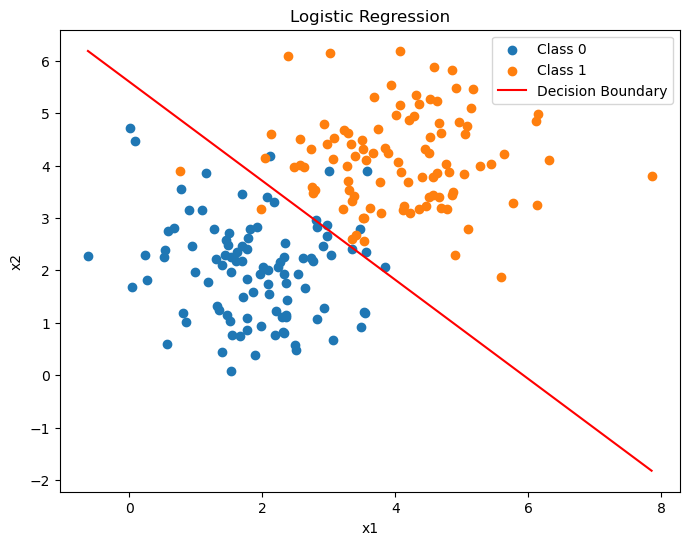

In [ ]:
# 6. Decision boundary ploi -
plt.figure(figsize=(8, 6))
plt.scatter(df[df.y==0]["x1"], df[df.y==0]["x2"], label="Class 0")
plt.scatter(df[df.y==1]["x1"], df[df.y==1]["x2"], label="Class 1")

# Decision boundary: thetaO + theta1*x1 + theta2*x2 = 0
x_boundary = np.linspace(df["x1"].min(), df["x1"].max(), 100)
y_boundary = -(theta[0] + theta[1]*x_boundary) / theta[2]
plt.plot(x_boundary, y_boundary, color="red", label="Decision Boundary")
plt.xlabel("x1")
plt.ylabel ("x2")
plt.legend()
plt.title("Logistic Regression")
plt.show()

### Multilogistic regression example

In [15]:
from matplotlib.colors import ListedColormap

#--- Step 1: Create synthetic dataset ---
X = np.array([
    [2, 3], [1, 5], [2, 8],
    [3, 1], [4, 2], [6, 1],
    [7, 5], [8, 7], [9, 6]
])
y = np.array([0, 0, 0, 1, 1, 1, 2, 2, 2])
df = pd.DataFrame(X, columns=['Feature1', 'Feature2'])
df['Class'] = y

#2. Step 2: one-hot encoding
def one_hot(y, num_classes):
    return np.eye(num_classes)[y]
y_one_hot = one_hot(y, 3)

#3. softmax fun
def softmax(z):
    exp_z = np.exp(z - np.max(z, axis=1, keepdims=True))
    return exp_z / exp_z.sum(axis=1, keepdims=True)

#4. Initialize weights and bias
n_features = X.shape[1]
n_classes = 3
np.random.seed(0)
W = np.random.randn(n_features, n_classes)
b = np.zeros((1, n_classes))

In [16]:
# --- Step 5: Define model and loss ---
def predict(X, W, b):
    return softmax(np.dot(X, W) + b)

def cross_entropy(y_true, y_pred):
    n_samples = y_true.shape[0]
    loss = -np.sum(y_true * np.log(y_pred + 1e-15)) / n_samples
    return loss

# --- Step 6: Train model using Gradient Descent ---
learning_rate = 0.1
epochs = 1000

for i in range(epochs):
    y_pred = predict(X, W, b)
    n_samples = X.shape[0]

    # Gradients
    dW = np.dot(X.T, (y_pred - y_one_hot)) / n_samples
    db = np.sum(y_pred - y_one_hot, axis=0, keepdims=True) / n_samples

    # Update weights
    W -= learning_rate * dW
    b -= learning_rate * db

    # Print loss every 200 epochs
    if i % 200 == 0:
        loss = cross_entropy(y_one_hot, y_pred)
        print(f'Epoch {i}, Loss: {loss:.4f}')

Epoch 0, Loss: 10.6751
Epoch 200, Loss: 0.0908
Epoch 400, Loss: 0.0514
Epoch 600, Loss: 0.0360
Epoch 800, Loss: 0.0278



Accuracy: 1.0

Confusion Matrix:
 Predicted  0  1  2
Actual            
0          3  0  0
1          0  3  0
2          0  0  3


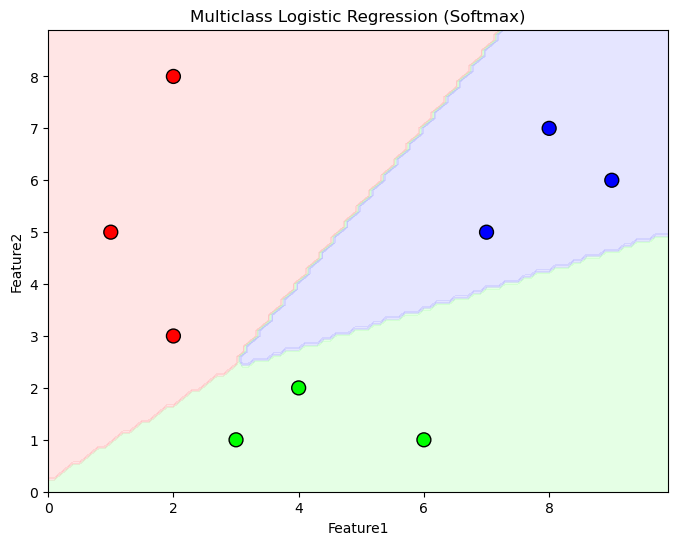

In [17]:
# --- Step 7: Predictions ---
y_pred_final = predict(X, W, b)
y_classes = np.argmax(y_pred_final, axis=1)

# --- Step 8: Metrics ---
accuracy = np.mean(y_classes == y)
print("\nAccuracy:", accuracy)

# Confusion Matrix
conf_matrix = pd.crosstab(pd.Series(y, name='Actual'),
                          pd.Series(y_classes, name='Predicted'))
print("\nConfusion Matrix:\n", conf_matrix)

# --- Step 9: Plot decision boundaries ---
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1),
                     np.arange(y_min, y_max, 0.1))

# Predict on grid points
grid_points = np.c_[xx.ravel(), yy.ravel()]
Z = np.argmax(predict(grid_points, W, b), axis=1)
Z = Z.reshape(xx.shape)

# Define color maps
cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])
cmap_bold = ListedColormap(['#FF0000', '#00FF00', '#0000FF'])

# Plot
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_light)
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=cmap_bold, edgecolor='k', s=100)
plt.title("Multiclass Logistic Regression (Softmax)")
plt.xlabel("Feature1")
plt.ylabel("Feature2")
plt.show()

#### Decision Tree

Accuracy: 0.9777777777777777

Confusion Matrix:
 [[19  0  0]
 [ 0 12  1]
 [ 0  0 13]]

Classification Report:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       1.00      0.92      0.96        13
   virginica       0.93      1.00      0.96        13

    accuracy                           0.98        45
   macro avg       0.98      0.97      0.97        45
weighted avg       0.98      0.98      0.98        45



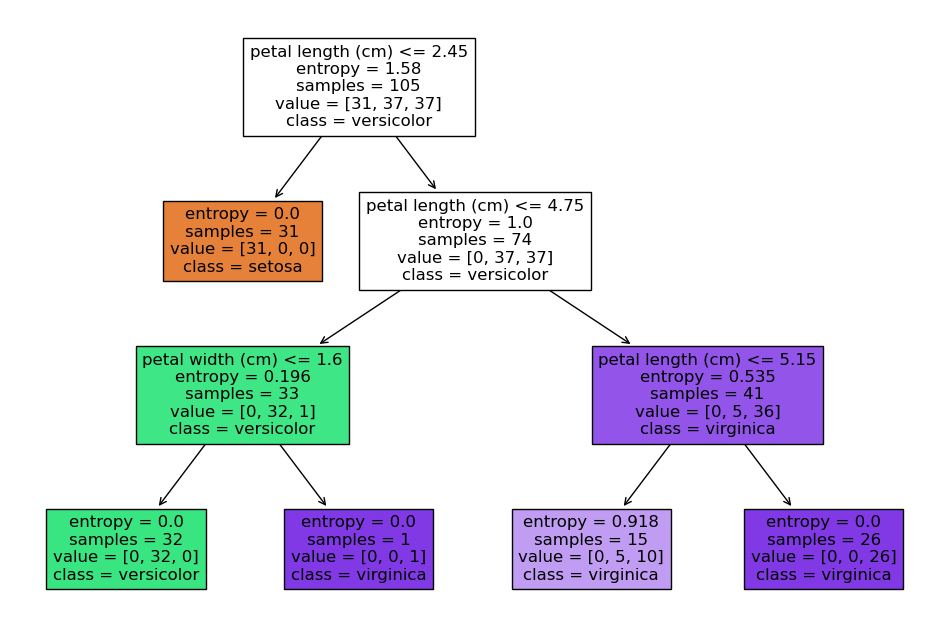

In [18]:
# Step 1: Import libraries
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Step 2: Load dataset
iris = load_iris()
X = iris.data
y = iris.target

# Step 3: Split into train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Step 4: Train Decision tree
tree = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42)
tree.fit(X_train, y_train)

# Step 5: Make predictions 
y_pred = tree.predict(X_test)

# Step 6: Metrics
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=iris.target_names))

# Step 7: Plot the decision tree
plt.figure(figsize=(12, 8))
plot_tree(tree, feature_names=iris.feature_names, class_names=iris.target_names, filled=True)
plt.show()

#### Support Vector Machine

Epoch 0, Loss: 7.6470
Epoch 200, Loss: 4.2509
Epoch 400, Loss: 3.1246
Epoch 600, Loss: 2.9778
Epoch 800, Loss: 2.8371

Accuracy: 0.875

Confusion Matrix:
 Predicted  -1   1
Actual           
-1          3   1
 1          0   4


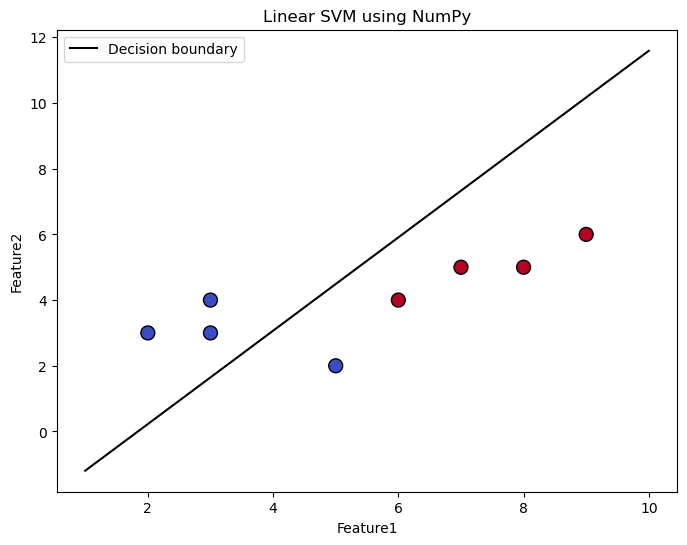

In [19]:
# SVM

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Step 1: create a simple 2-class dataset
data = {
    'feature1': [2, 3, 3, 5, 6, 7, 8, 9],
    'feature2': [3, 3, 4, 2, 4, 5, 5, 6],
    'class': [0, 0, 0, 0, 1, 1, 1, 1]  # two classes: 0 and 1
}

df = pd.DataFrame(data)
X = df[['feature1', 'feature2']].values
y = df['class'].values
y = np.where(y == 0, -1, 1)  # convert labels to -1 and 1

# Step 2: Initialize parameters
epochs = 1000
learning_rate = 0.001
lambda_param = 0.01
w = np.zeros(X.shape[1])  # weight vector
b = 0  # bias

# Step 3: Train linear SVM using gradient descent (hinge loss)
for epoch in range(epochs):
    for idx, xi in enumerate(X):
        condition = y[idx] * (np.dot(xi, w) + b) >= 1
        if condition:
            w -= learning_rate * (2 * lambda_param * w)
        else:
            w -= learning_rate * (2 * lambda_param * w - np.dot(xi, y[idx]))
            b -= learning_rate * (-y[idx])
    
    # Track loss every 200 epochs
    if epoch % 200 == 0:
        distances = 1 - y * (np.dot(X, w) + b)
        distances = np.where(distances > 0, distances, 0)
        loss = 0.5 * lambda_param * np.dot(w, w) + np.sum(distances)
        print(f'Epoch {epoch}, Loss: {loss:.4f}')

# Step 4: Predictions
def predict(X, w, b):
    linear_output = np.dot(X, w) + b
    return np.where(linear_output >= 0, 1, -1)

y_pred = predict(X, w, b)

# Step 5: Metrics
accuracy = np.mean(y_pred == y)
conf_matrix = pd.crosstab(pd.Series(y, name='Actual'), pd.Series(y_pred, name='Predicted'))
print("\nAccuracy:", accuracy)
print("\nConfusion Matrix:\n", conf_matrix)

# Step 6: Plot decision boundary
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
xx = np.linspace(x_min, x_max, 100)
yy = -(w[0] * xx + b) / w[1]  # decision boundary

plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.coolwarm, s=100, edgecolor='k')
plt.plot(xx, yy, 'k-', label='Decision boundary')
plt.title('Linear SVM using NumPy')
plt.xlabel('Feature1')
plt.ylabel('Feature2')
plt.legend()
plt.show()

### Example: K-Nearest Neighbour, 1

In [20]:
from collections import Counter

Predicted Class:  [0 0 0 1 1 1 2 2 2]
Accuracy: 1.0
 (nConfusion Matrix:
    0  1  2
0  3  0  0
1  0  3  0
2  0  0  3


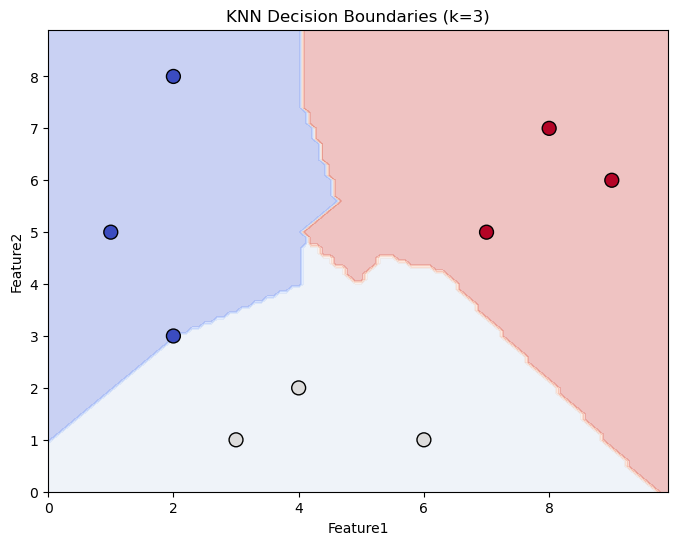

In [21]:
data = {
    'Feature1': [2,1,2,3,4,6,7,8,9],
    'Feature2': [3,5,8,1,2,1,5,7,6],
    'Class1': [0,0,0,1,1,1,2,2,2]
}

df = pd.DataFrame(data)
X = df[['Feature1','Feature2']].values
y = df['Class1'].values

def euclidean_distance(a,b):
    return np.sqrt(np.sum((a-b)**2, axis=1))

def knn_predicts(X_train, y_train, X_test, k=3):
    predictions = []
    for x in X_test:
        distances = euclidean_distance(X_train, x)
        k_indices = distances.argsort()[:k]
        k_labels = y_train[k_indices]
        most_common = Counter(k_labels).most_common(1)[0][0]
        predictions.append(most_common)
    return np.array(predictions)

k = 3
y_pred = knn_predicts(X,y,X,k=k)
print("Predicted Class: ", y_pred)

def accuracy (y_true, y_pred):
    return np.mean (y_true == y_pred)

def confusion_matrix(y_true, y_pred):
    classes = np.unique(y_true)
    matrix = np.zeros((len(classes), len(classes)), dtype=int)
    for i, cls in enumerate(classes):
        for j, pred_cls in enumerate(classes):
            matrix[i,j] = np.sum((y_true==cls) & (y_pred==pred_cls))
    return pd.DataFrame(matrix, index=classes, columns=classes)
acc = accuracy (y, y_pred)
cm = confusion_matrix(y, y_pred)
print("Accuracy:", acc)
print(" (nConfusion Matrix:\n", cm)
# --- Step 5: Plot decision boundaries ---
x_min, x_max = X[:, 0].min() - 1, X[:,0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:,1].max() + 1
xx, yy = np.meshgrid (np.arange(x_min, x_max, 0.1),np.arange(y_min, y_max, 0.1))
grid_points = np.c_[xx.ravel(), yy.ravel()]
Z = knn_predicts(X, y, grid_points, k=k)
Z = Z.reshape(xx.shape)

plt.figure(figsize=(8,6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
plt.scatter(X[:,0], X[:,1], c=y, cmap=plt.cm.coolwarm, edgecolor='k', s=100)
plt.title(f'KNN Decision Boundaries (k={k})')
plt.xlabel('Feature1')
plt.ylabel('Feature2')
plt.show()

### KNN, Ex 2

Confusion Matrix:
 [[19  0  0]
 [ 0  8  5]
 [ 0  3 10]]

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        19
           1       0.73      0.62      0.67        13
           2       0.67      0.77      0.71        13

    accuracy                           0.82        45
   macro avg       0.80      0.79      0.79        45
weighted avg       0.82      0.82      0.82        45



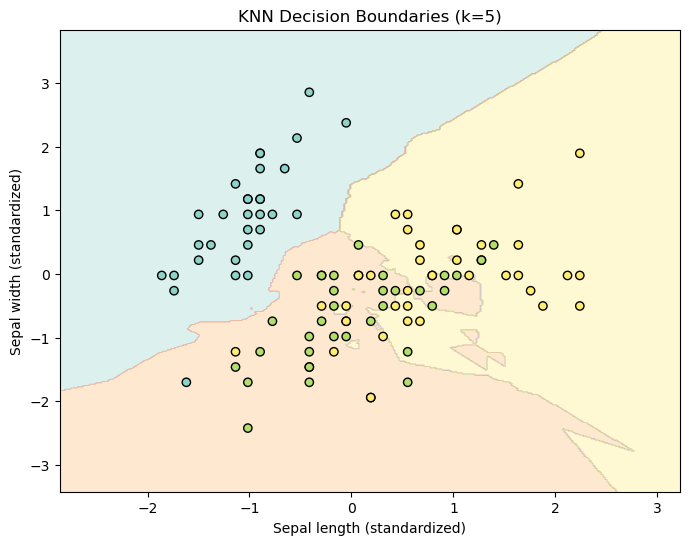

In [22]:
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Load Iris dataset (only first 2 features for visualization)
iris = datasets.load_iris()
X = iris.data[:, :2] # sepal length and width
y = iris.target


# Train/Test split
 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3,random_state=42)

# Standardize features (important for KNN)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


# Create KNN model (k=5)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

# Predictions

y_pred = knn.predict(X_test)

print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

print("\nClassification Report:\n", classification_report(y_test, y_pred))

# Plot decision boundaries

x_min, x_max = X_train[:, 0].min() - 1, X_train[:, 0].max() + 1
y_min, y_max = X_train[:, 1].min() - 1, X_train[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
np.arange(y_min, y_max, 0.02))
Z = knn.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.Set3)
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, edgecolor='k',cmap=plt.cm.Set3)
plt.title("KNN Decision Boundaries (k=5)")
plt.xlabel("Sepal length (standardized)")
plt.ylabel("Sepal width (standardized)")
plt.show()